# 🎨 3W Dataset Visualization Techniques

This notebook demonstrates advanced visualization techniques for the 3W oil well dataset using dimensionality reduction methods and statistical analysis.

**Key Features:**
- **complete vizualizzation**: vizualizar samples of each chosen class
- **t-SNE & UMAP**: Dimensionality reduction for pattern discovery with parameter optimization

**Prerequisites:**
- Run `1_data_treatment.ipynb` first to generate windowed time series data
- Ensure processed data is saved in pickle format for optimal performance

**Note**: this demonstration was developed using the **3W Dataset 2.0.0** and the **3W Toolkit 3.2.1**; results may differ if other versions were used.

> 📖 **Companion book** — this notebook illustrates the visualization discussion of **Chapter 6** (§*Visualização*: PCA, t-SNE and UMAP) of Lopes et al. (2026), *Aprendizado de Mundo Aberto em Poços de Petróleo* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)), plus the data discussion of **Chapter 3**. See **Appendix E** for the map between notebooks and chapters.
>
> 🧰 **3W Toolkit** — the windows come from the toolkit `ParquetDataset`, `Normalize` and `Windowing` (notebook 1), and this notebook compares two inputs for the projections: the raw flattened window (900 values) and **toolkit `StatisticalFeatures`** (30 values). t-SNE and UMAP are not in the toolkit, so they stay as our own helpers. For plotting raw 3W series (single and multiple series, correlation heatmaps, 3W-specific charts) see the toolkit's [data visualization tutorial](../introduction_to_3w_toolkit_v2.0.0/6_data_visualization.ipynb).

In [1]:
# Setup Environment and Imports
import time
import sys

start_time = time.time()

print("🎨 Loading 3W Dataset for Visualization Analysis")
print("=" * 60)

# Add src to path and import modules
sys.path.append("src")

try:
    print("📦 Importing modules...", end=" ", flush=True)
    from src.data_persistence import DataPersistence
    from src.visualization import DimensionalityReductionVisualizer
    from src import config
    import numpy as np

    print("✅")

    print("🔧 Initializing components...", end=" ", flush=True)
    persistence = DataPersistence(base_dir=config.PROCESSED_DATA_DIR, verbose=False)
    dim_reducer = DimensionalityReductionVisualizer()
    print("✅")

    print("📁 Configuration Summary:")
    print(f"   • Save format: {config.SAVE_FORMAT}")
    print(f"   • Data directory: {config.PROCESSED_DATA_DIR}")

except Exception as e:
    print(f"❌ Setup failed: {e}")
    raise

🎨 Loading 3W Dataset for Visualization Analysis
📦 Importing modules... 

✅
🔧 Initializing components... 

✅
📁 Configuration Summary:
   • Save format: pickle
   • Data directory: processed_data


## Visualization for Time Series

**Challenges with high-dimensional time series:**
- **Curse of dimensionality** - Hard to visualize >3D data
- **Pattern discovery** - Hidden structures in sensor data
- **Class separability** - Understanding which features distinguish faults

**Visualization benefits:**
- **Data understanding** - See actual sensor patterns per fault type
- **Algorithm selection** - Choose models based on data structure
- **Quality assessment** - Identify noise, outliers, mislabeled data
- **Feature engineering** - Discover which sensors are most informative

In [2]:
# Load Windowed Data
try:
    print("📊 Loading windowed test data...")
    load_start = time.time()

    # Load data from first available fold using the existing visualizer
    test_dfs, test_classes, metadata = dim_reducer.load_windowed_data(
        persistence, config
    )

    load_time = time.time() - load_start
    print("✅ Data loaded successfully!")
    print(f"   • Format: {metadata['format']}")
    print(f"   • Fold: {metadata['fold_number']}")
    print(f"   • Windows: {metadata['windows_count']}")
    print(f"   • Load time: {load_time:.3f}s")

    # Quick data validation
    if test_dfs and len(test_dfs) > 0:
        sample_window = test_dfs[0]
        sample_class = test_classes[0] if test_classes else "Unknown"

except Exception as e:
    print(f"❌ Data loading failed: {e}")
    print("💡 Troubleshooting:")
    print("   • Ensure '1_data_treatment.ipynb' completed successfully")
    print("   • Check if processed_data directory exists")

    test_dfs, test_classes = None, None
    import traceback

    traceback.print_exc()

📊 Loading windowed test data...
📊 Loading windowed data...
   • Windowed directory: processed_data\cv_splits\windowed
   • Loading from fold_1


   ✅ Loaded 5384 windows from fold 1
✅ Data loaded successfully!
   • Format: pickle
   • Fold: 1
   • Windows: 5384
   • Load time: 0.609s


## Data Loading for Visualization

**Key considerations:**
- **Memory management** - Time series windows can be large
- **Sampling strategy** - Balance between detail and performance
- **Data validation** - Ensure windowed data maintains temporal structure

**Loading priorities:**
- **Test data focus** - Analyze real data that models will encounter
- **Class balance** - Ensure all fault types represented
- **Metadata preservation** - Keep windowing and preprocessing information

## Complete Data Visualization

**Purpose:**
- **Temporal patterns** - See how sensors behave over time for each fault
- **Correlation analysis** - Understand relationships between pressure/temperature
- **Baseline establishment** - Compare normal vs abnormal behavior

**What to look for:**
- **Normal class (0)** - Stable, regular patterns
- **Fault classes (1-8)** - Distinctive anomalous behaviors
- **Sensor interactions** - How different sensors respond to same fault

🎨 Window Sensor Data Visualization
🏷️ Processing class labels...


🏷️ Original class distribution: {np.int16(0): np.int64(1608), np.int16(1): np.int64(2), np.int16(2): np.int64(3), np.int16(3): np.int64(242), np.int16(4): np.int64(136), np.int16(5): np.int64(1), np.int16(6): np.int64(7), np.int16(7): np.int64(7), np.int16(8): np.int64(23), np.int16(9): np.int64(20), np.int16(101): np.int64(52), np.int16(102): np.int64(20), np.int16(105): np.int64(58), np.int16(106): np.int64(3), np.int16(107): np.int64(2826), np.int16(108): np.int64(272), np.int16(109): np.int64(104)}
🔄 Mapped 3335 points with transient classes
🏷️ Mapped class distribution: {np.int64(0): np.int64(1608), np.int64(1): np.int64(54), np.int64(2): np.int64(23), np.int64(3): np.int64(242), np.int64(4): np.int64(136), np.int64(5): np.int64(59), np.int64(6): np.int64(10), np.int64(7): np.int64(2833), np.int64(8): np.int64(295), np.int64(9): np.int64(124)}


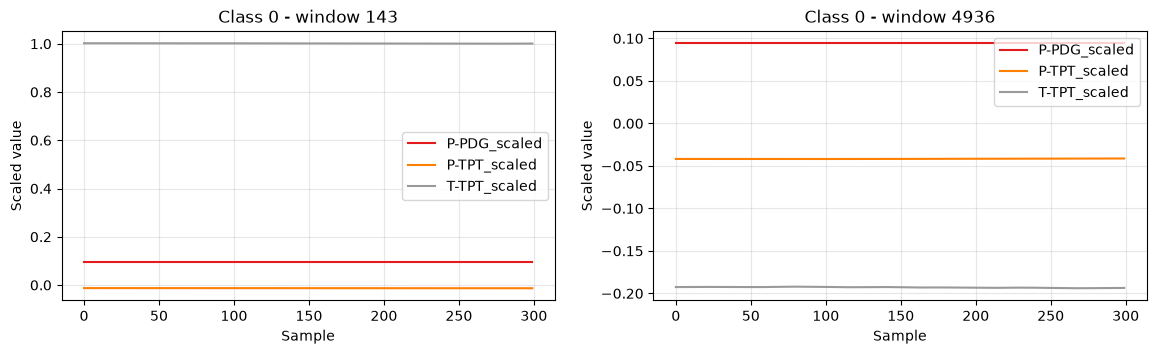

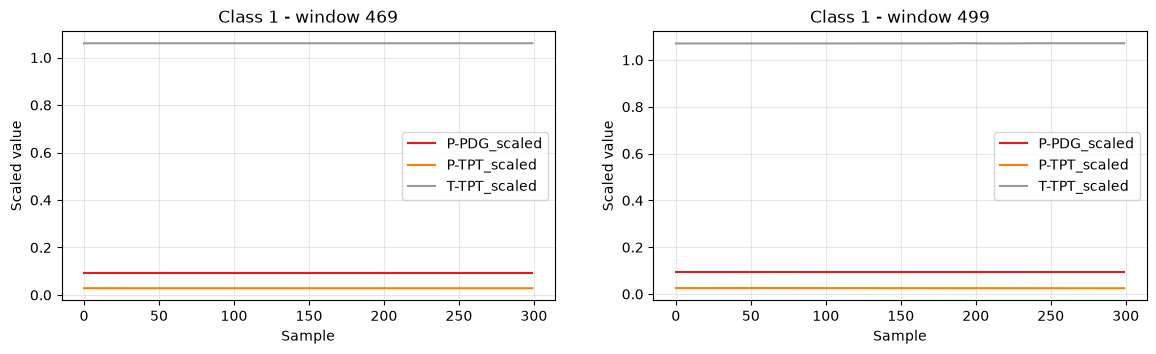

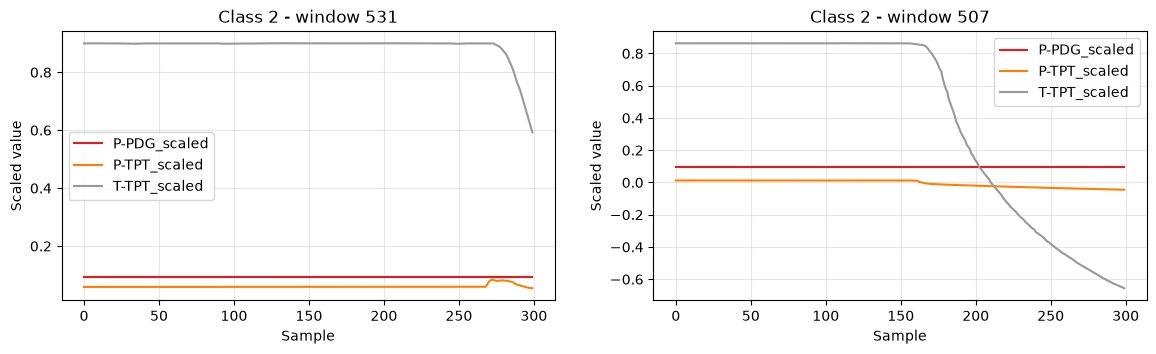

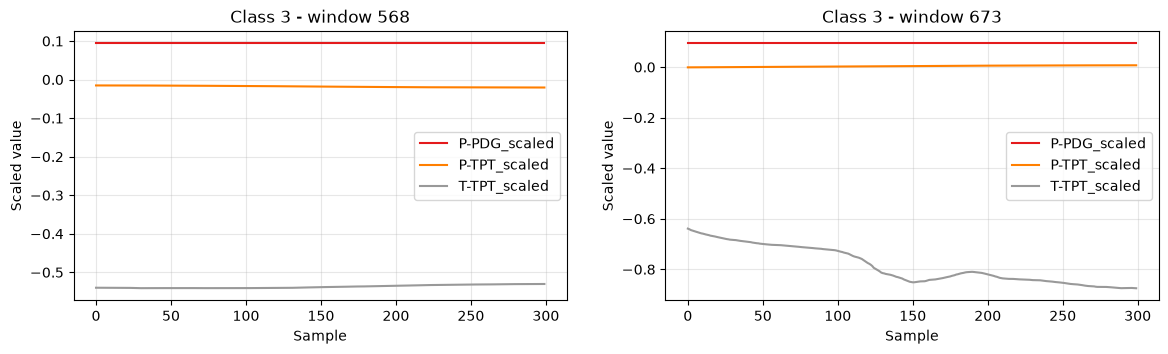

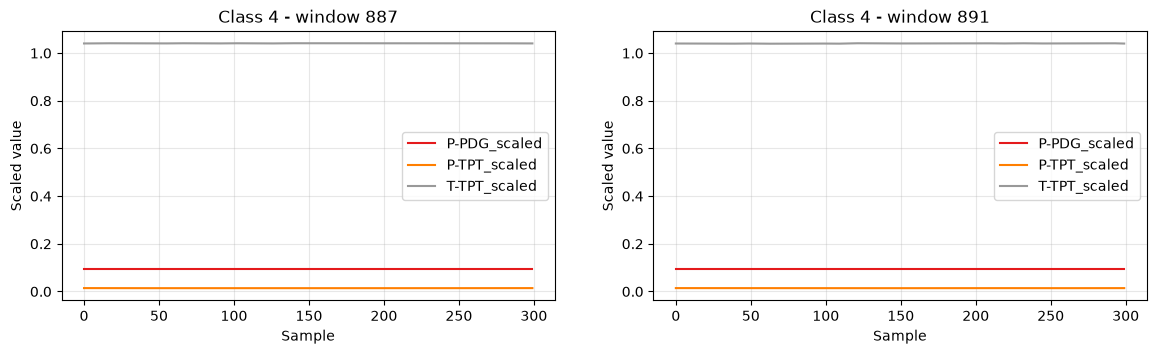

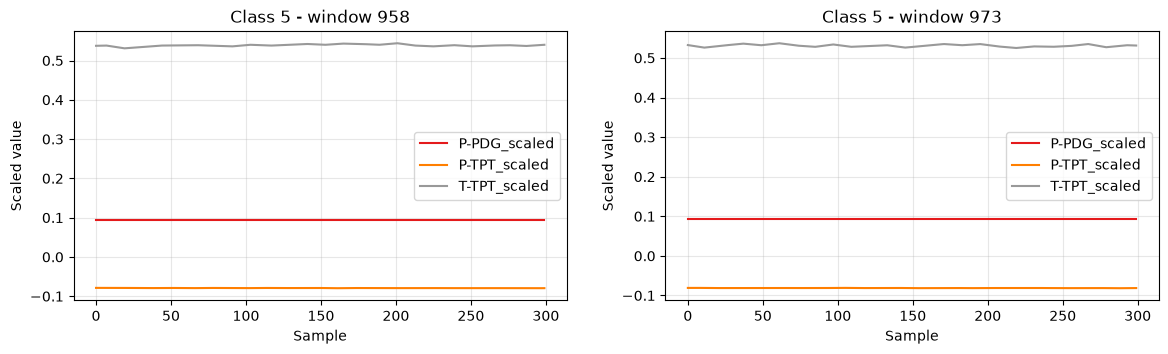

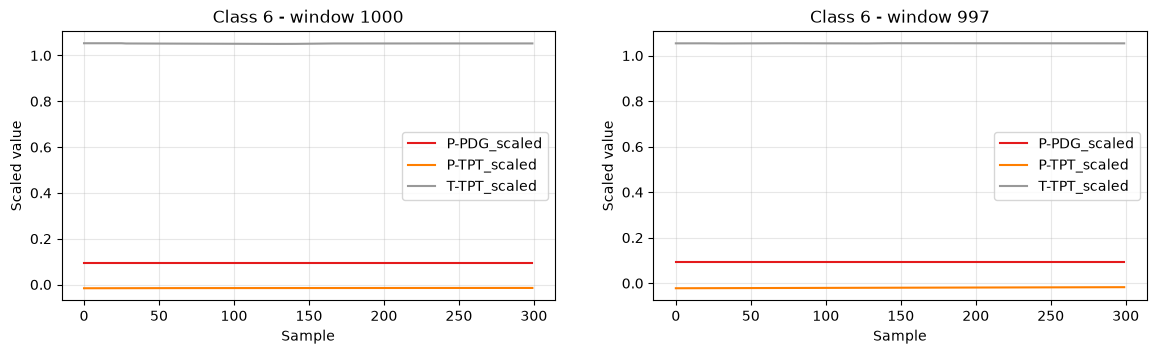

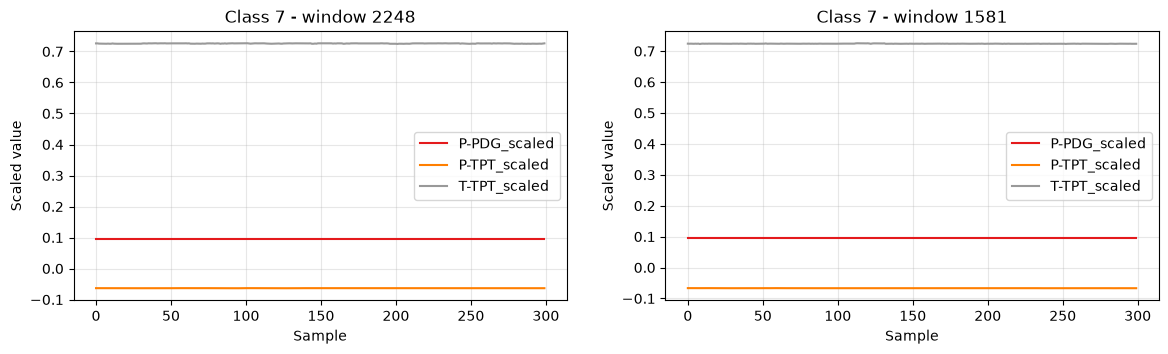

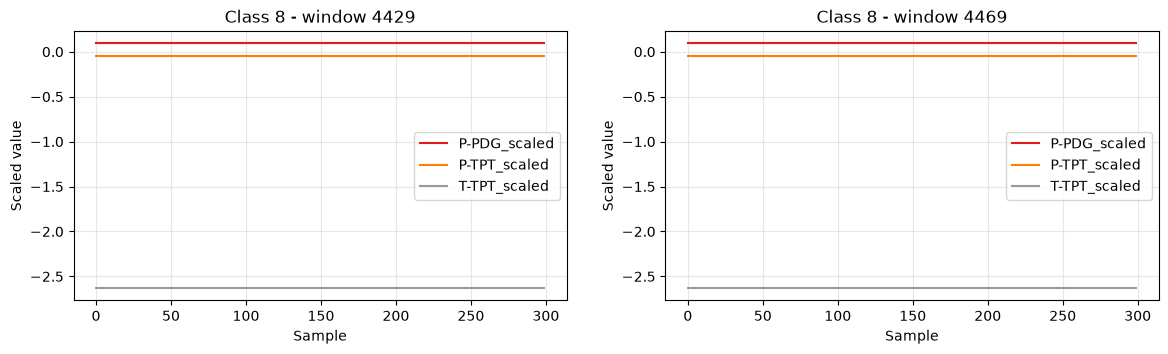

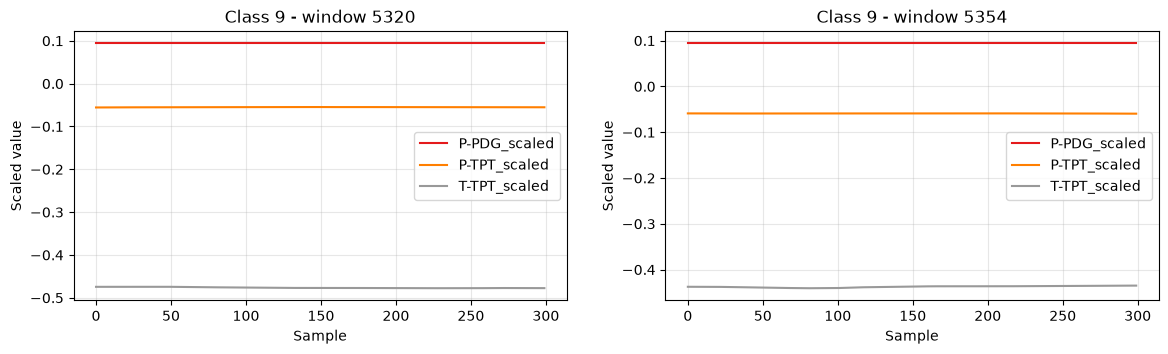

In [3]:
# Complete Visualization: Sample Sensor Data for Each Class
import matplotlib.pyplot as plt
from ThreeWToolkit.data_visualization import PlotMultipleSeries

if test_dfs is not None and "test_classes" in locals():
    print("🎨 Window Sensor Data Visualization")
    print("=" * 60)

    # Extract and map class labels first
    mapped_classes = dim_reducer.extract_and_map_classes(test_dfs, test_classes)

    rng = np.random.default_rng(42)  # reproducible choice of the windows
    samples_per_class = 2
    for class_label in sorted(set(mapped_classes)):
        positions = [i for i, c in enumerate(mapped_classes) if c == class_label]
        chosen = rng.choice(positions, size=min(samples_per_class, len(positions)), replace=False)
        # One figure per class, one panel per window (PlotMultipleSeries draws on the given axis)
        fig, axes = plt.subplots(1, len(chosen), figsize=(7 * len(chosen), 3.5), squeeze=False)
        for ax, i in zip(axes[0], chosen):
            window = test_dfs[i]
            columns = [c for c in window.columns if c != "class"]
            PlotMultipleSeries(
                series_list=[window[c] for c in columns],
                labels=columns,
                title=f"Class {class_label} - window {i}",
                xlabel="Sample",
                ylabel="Scaled value",
            ).plot(ax=ax)
        plt.show()
else:
    print("❌ Cannot create complete visualizations: No test data available")
    print("Please ensure the data loading completed successfully")

## Data Preprocessing for Dimensionality Reduction

**Why preprocess for visualization?**
- **Feature standardization** - Ensure all sensors contribute equally
- **Sampling strategy** - Balance computational cost vs. detail
- **Format transformation** - Convert time windows to feature vectors

**Steps:**
1. **Flatten windows** - Convert 2D time series to 1D feature vectors
2. **Standardize features** - Zero mean, unit variance
3. **Intelligent sampling** - Balance classes while reducing dataset size

In [4]:
# Extract and Process Class Labels
if test_dfs is not None:
    try:
        # Extract and map class labels using existing methods
        mapped_classes = dim_reducer.extract_and_map_classes(test_dfs, test_classes)
        print("✅ Class processing complete")

    except Exception as e:
        print(f"❌ Class processing failed: {e}")
        mapped_classes = None

🏷️ Processing class labels...
🏷️ Original class distribution: {np.int16(0): np.int64(1608), np.int16(1): np.int64(2), np.int16(2): np.int64(3), np.int16(3): np.int64(242), np.int16(4): np.int64(136), np.int16(5): np.int64(1), np.int16(6): np.int64(7), np.int16(7): np.int64(7), np.int16(8): np.int64(23), np.int16(9): np.int64(20), np.int16(101): np.int64(52), np.int16(102): np.int64(20), np.int16(105): np.int64(58), np.int16(106): np.int64(3), np.int16(107): np.int64(2826), np.int16(108): np.int64(272), np.int16(109): np.int64(104)}
🔄 Mapped 3335 points with transient classes
🏷️ Mapped class distribution: {np.int64(0): np.int64(1608), np.int64(1): np.int64(54), np.int64(2): np.int64(23), np.int64(3): np.int64(242), np.int64(4): np.int64(136), np.int64(5): np.int64(59), np.int64(6): np.int64(10), np.int64(7): np.int64(2833), np.int64(8): np.int64(295), np.int64(9): np.int64(124)}
✅ Class processing complete


## Dimensionality Reduction Theory

**The challenge:** Time series windows create high-dimensional data (e.g., 100 timesteps × 5 sensors = 500 features)

**Dimensionality reduction goals:**
- **Visualization** - Project to 2D/3D for human interpretation
- **Pattern discovery** - Reveal hidden structures and clusters
- **Noise reduction** - Focus on most informative dimensions

**Method comparison:**
- **t-SNE** - Excellent for cluster visualization, preserves local neighborhoods
- **UMAP** - Faster, preserves both local and global structure, more deterministic
- **Parameter sensitivity** - Both require tuning for optimal results

**Applications:**
- **Class separability** - See if fault types form distinct clusters
- **Outlier detection** - Identify unusual samples
- **Feature importance** - Understand which sensor patterns matter most

> 📖 **In the book — Chapter 6, §*Visualização* ("rule of use").** *No quantitative conclusion of the book rests on a two-dimensional projection*: projections only **illustrate** a conclusion already established by a metric. In t-SNE, the distances between clusters in the plot have no meaning, and the result depends on the perplexity and on the random seed; UMAP preserves more of the global structure, but shares the limitation — it is a tool of **inspection**, not of **measurement**.

In [5]:
# Intelligent Sampling and Feature Extraction
if mapped_classes is not None:
    try:
        # Perform intelligent sampling using existing methods
        selected_test_dfs, selected_classes, sampling_summary = (
            dim_reducer.intelligent_sampling_for_visualization(
                test_dfs, mapped_classes, config
            )
        )

        # Extract and standardize features
        X_scaled, y_labels, scaler = dim_reducer.prepare_features_for_visualization(
            selected_test_dfs, selected_classes
        )

        print("\n📈 Final Dataset Summary:")
        print(f"   • Samples: {X_scaled.shape[0]} (balanced)")
        print(f"   • Features: {X_scaled.shape[1]} (standardized)")
        print(f"   • Classes: {sorted(np.unique(y_labels))}")
        print(f"   • Memory: {X_scaled.nbytes / 1024 / 1024:.2f} MB")

        unique_classes = np.unique(y_labels)
        print("✅ Data preparation complete - ready for visualization!")

    except Exception as e:
        print(f"❌ Feature extraction failed: {e}")
        X_scaled, y_labels = None, None
        import traceback

        traceback.print_exc()
else:
    X_scaled, y_labels = None, None

🎯 Performing intelligent sampling...
   • Selected 400 windows
   • Sampling summary: {0: {'available': 1608, 'sampled': 100}, 3: {'available': 242, 'sampled': 100}, 4: {'available': 136, 'sampled': 100}, 8: {'available': 295, 'sampled': 100}}
🔄 Preparing features for visualization...
   • Features: 3 sensors × 300 timesteps


   • Feature matrix: (400, 900)
   • Memory usage: 2.75 MB

📈 Final Dataset Summary:
   • Samples: 400 (balanced)
   • Features: 900 (standardized)
   • Classes: [np.int64(0), np.int64(3), np.int64(4), np.int64(8)]
   • Memory: 2.75 MB
✅ Data preparation complete - ready for visualization!


## Toolkit first: a feature view of the windows

A window of 300 steps × 3 sensors is a 900-dimensional vector. The toolkit offers a compact alternative: `StatisticalFeatures` summarizes each sensor of each window with statistics (mean, std, quantiles, skewness, ...), giving **10 numbers per sensor, 30 per window**. It expects the toolkit windowed layout: a `(window, variable)` index with the time steps as columns.

Below, the same windows are projected with the same t-SNE (perplexity 30) from both inputs. The rest of the notebook uses the flattened window, as in the book; this comparison shows how much of the structure a few statistics already keep.

Flattened window: (400, 900) | StatisticalFeatures: (400, 30)
Columns: ['mean_P-PDG_scaled', 'mean_P-TPT_scaled', 'mean_T-TPT_scaled', 'std_P-PDG_scaled', 'std_P-TPT_scaled', 'std_T-TPT_scaled'] ...


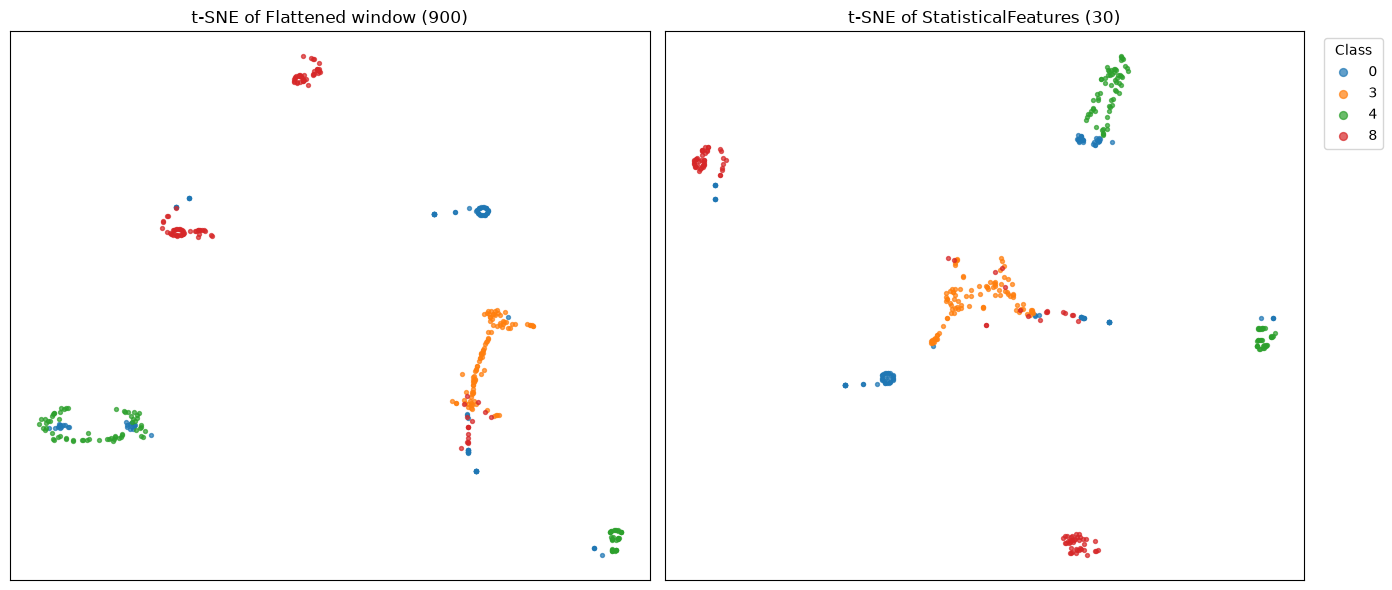

In [6]:
# ============================================================
# TOOLKIT STATISTICAL FEATURES vs THE FLATTENED WINDOW
# ============================================================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from ThreeWToolkit.core.dataset_outputs import DatasetOutputs
from ThreeWToolkit.feature_extraction import StatisticalConfig

if X_scaled is not None and y_labels is not None:
    sensor_cols = [c for c in selected_test_dfs[0].columns if c != "class"]

    # Windows -> toolkit layout: index (window, variable), columns = time steps
    windows = np.stack([w[sensor_cols].to_numpy().T for w in selected_test_dfs])
    index = pd.MultiIndex.from_product(
        (range(len(windows)), sensor_cols), names=["window", "variable"]
    )
    windowed = pd.DataFrame(windows.reshape(-1, windows.shape[-1]), index=index)

    extractor = StatisticalConfig().build()  # all 10 statistics
    features = extractor.transform(
        DatasetOutputs(signal=windowed, label=None, metadata={})
    ).signal
    print(f"Flattened window: {X_scaled.shape} | StatisticalFeatures: {features.shape}")
    print("Columns:", list(features.columns[:6]), "...")

    X_stats = StandardScaler().fit_transform(features.to_numpy())
    labels = np.asarray(y_labels)[: len(X_stats)]

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, (name, data) in zip(
        axes, (("Flattened window (900)", X_scaled), ("StatisticalFeatures (30)", X_stats))
    ):
        embedding = TSNE(
            n_components=2, perplexity=30, learning_rate=200, random_state=config.RANDOM_SEED
        ).fit_transform(data)
        for cls in sorted(np.unique(labels), key=str):
            mask = labels == cls
            ax.scatter(embedding[mask, 0], embedding[mask, 1], s=8, alpha=0.7, label=str(cls))
        ax.set_title(f"t-SNE of {name}")
        ax.set_xticks([])
        ax.set_yticks([])
    axes[1].legend(title="Class", markerscale=2, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
else:
    print("❌ No processed data available")

### The projections of the book

From here on, the same four t-SNE and four UMAP configurations of the book are applied to the **flattened window**, using our own helpers (`DimensionalityReductionVisualizer`).

## t-SNE Implementation

**t-SNE (t-Distributed Stochastic Neighbor Embedding):**
- **Local structure focus** - Preserves neighborhoods between similar points
- **Non-linear mapping** - Can reveal complex, curved decision boundaries
- **Perplexity parameter** - Controls local vs global emphasis (typical: 5-50)

**Strengths:**
- **Excellent clustering** - Clear separation of different classes
- **Intuitive results** - Often produces visually appealing clusters

**Limitations:**
- **Slow computation** - O(n²) complexity
- **Random initialization** - Results can vary between runs
- **Global structure loss** - May not preserve overall data relationships

🔮 t-SNE: Non-linear Dimensionality Reduction
🔮 Running t-SNE analysis...
   • t-SNE #1: perplexity=30, lr=200...


     ✅ Completed in 0.4s
   • t-SNE #2: perplexity=10, lr=100...


     ✅ Completed in 0.3s
   • t-SNE #3: perplexity=50, lr=300...


     ✅ Completed in 0.4s
   • t-SNE #4: perplexity=30, lr=500...


     ✅ Completed in 0.4s


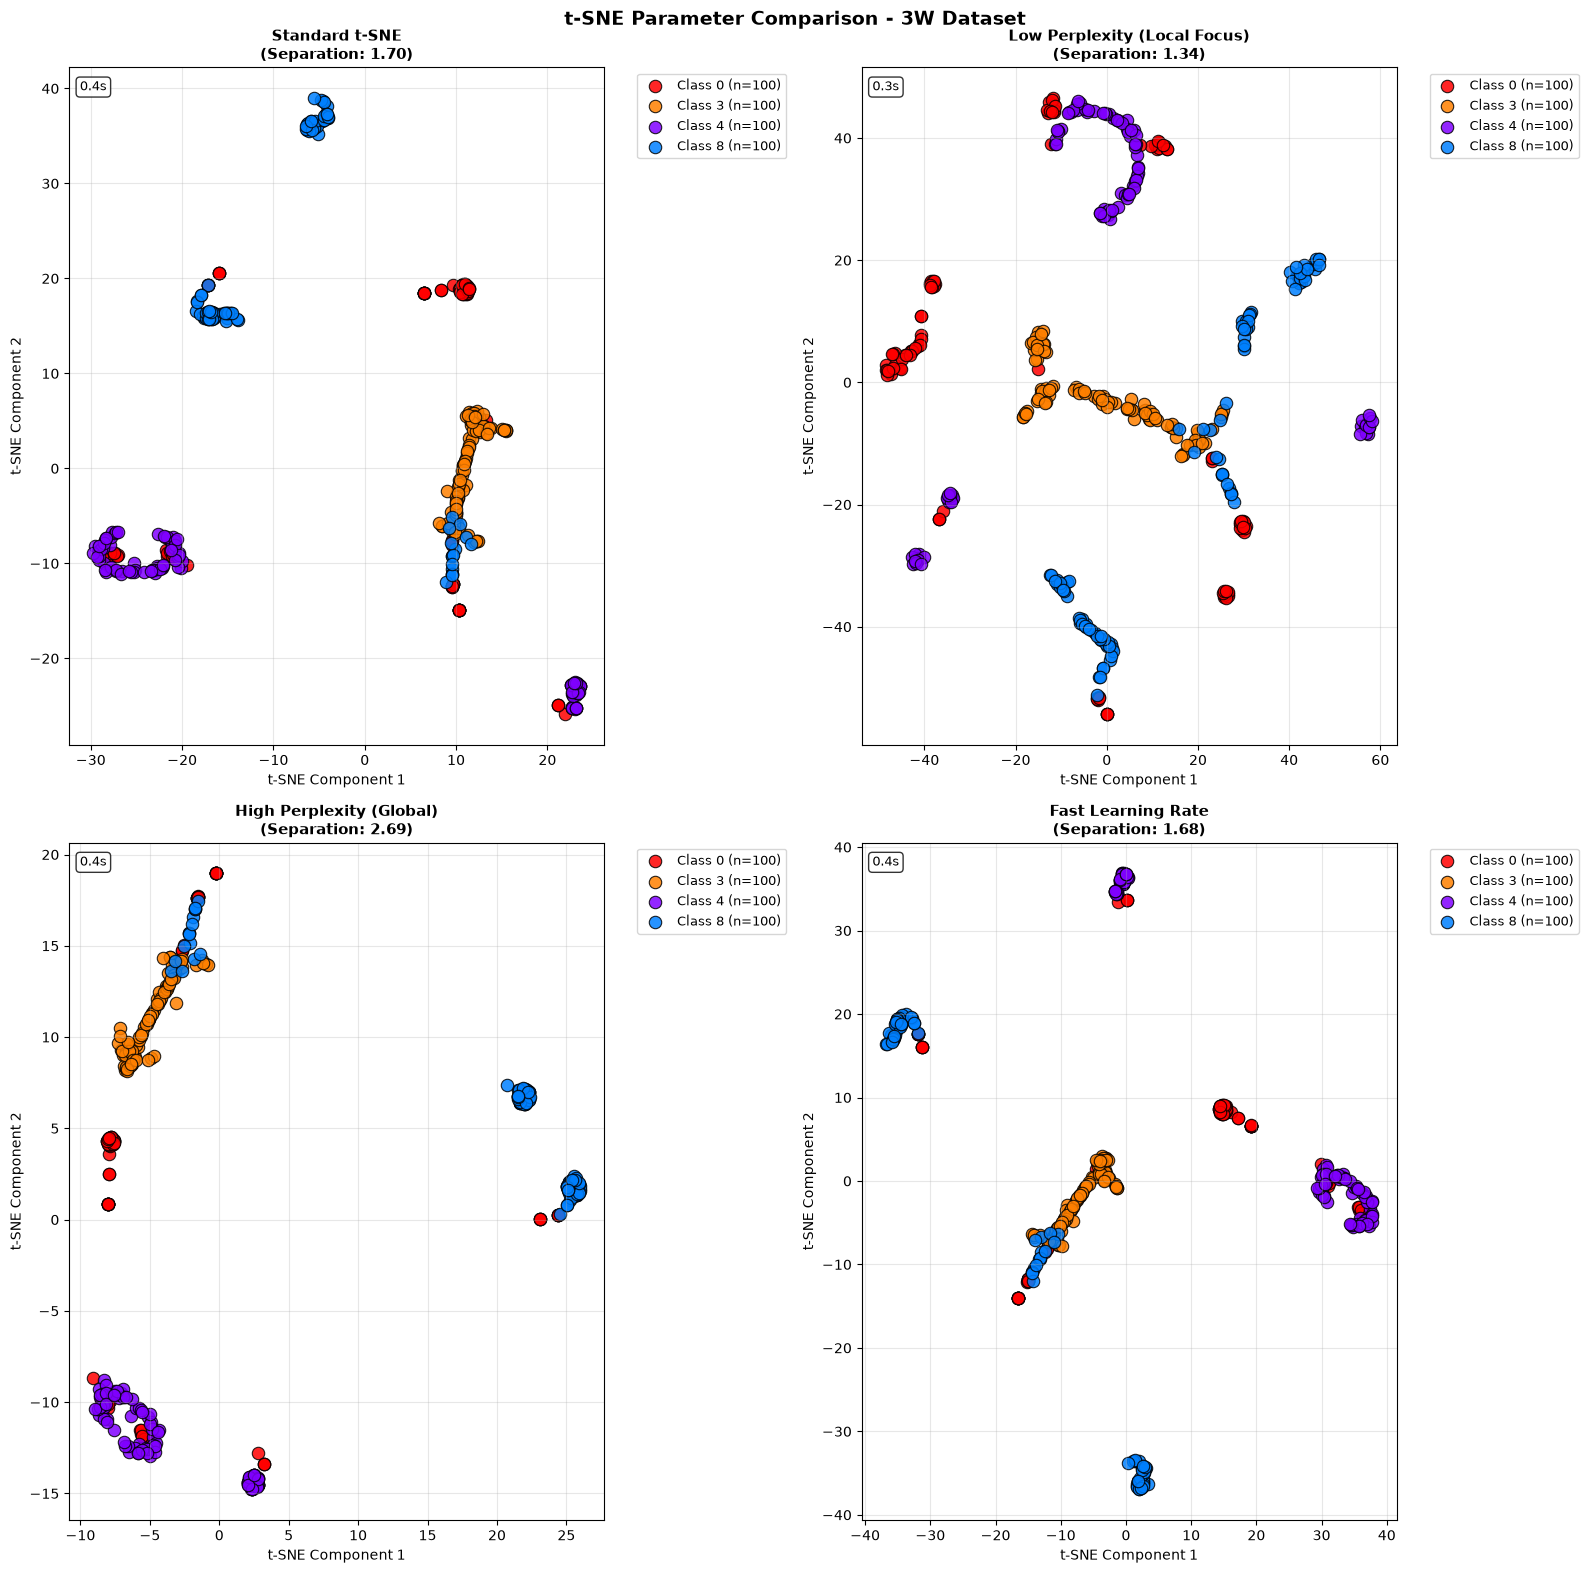


📊 t-SNE Analysis Results:
⚡ Configuration Performance:
   • Config 1: 0.4s
   • Config 2: 0.3s ⚡ Fastest
   • Config 3: 0.4s
   • Config 4: 0.4s


In [7]:
# t-SNE Visualization Analysis
if X_scaled is not None and y_labels is not None:
    print("🔮 t-SNE: Non-linear Dimensionality Reduction")
    print("=" * 60)

    # Run t-SNE analysis using existing methods
    tsne_results = dim_reducer.run_tsne_analysis(X_scaled, y_labels)

    # Create visualizations
    fig = dim_reducer.plot_dimensionality_reduction_results(
        tsne_results, y_labels, "t-SNE"
    )

    # Print performance summary
    dim_reducer.print_dimensionality_reduction_summary(tsne_results, "t-SNE")

else:
    print("❌ Cannot run t-SNE: No processed data available")
    print("Please ensure the data preparation completed successfully")

## Visualization Insights & Next Steps

**What we learned:**
- **Class separability** - How well different fault types can be distinguished
- **Data quality** - Identified outliers, noise, and potential mislabeling
- **Feature relevance** - Which sensor combinations are most informative
- **Algorithm suitability** - Whether linear or non-linear models are needed

**Actionable insights for ML:**
- **Well-separated clusters** → Simple classifiers (SVM, Random Forest) may work well
- **Complex boundaries** → Deep learning or ensemble methods needed
- **Overlapping classes** → Feature engineering or data augmentation required
- **Clear patterns** → Good prospects for accurate fault detection

**Next steps:**
- **Unsupervised learning** (notebook 3) - Explore anomaly detection
- **Supervised learning** (notebook 4) - Build classification models
- **Feature engineering** - Based on discovered patterns

# NEXT STEPS - UMAP

## UMAP Implementation

**UMAP (Uniform Manifold Approximation and Projection):**
- **Global + local structure** - Preserves both neighborhood and overall topology
- **Faster computation** - More scalable to large datasets
- **Deterministic** - Consistent results with same parameters

**Key parameters:**
- **n_neighbors** - Local neighborhood size (typical: 5-50)
- **min_dist** - Minimum distance between points in 2D space
- **metric** - Distance function (euclidean, cosine, etc.)

**Advantages:**
- **Speed** - Much faster than t-SNE for large datasets
- **Stability** - More consistent results across runs
- **Interpretability** - Better preserves global relationships

In [8]:
# Check UMAP Availability
try:
    import umap

    umap_available = True
    print("✅ UMAP library available")
except ImportError:
    umap_available = False
    print("❌ UMAP not available")
    print('📦 Install it with: uv pip install -e "../../.[resources]"')
    print("⚠️ Continuing without UMAP")

✅ UMAP library available


🚀 UMAP: Uniform Manifold Approximation
🚀 Running UMAP analysis...
   • UMAP #1: neighbors=15, dist=0.1...


C:\Users\LCCV\Documents\GitHub\3W\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


     ✅ Completed in 10.0s
   • UMAP #2: neighbors=5, dist=0.0...


C:\Users\LCCV\Documents\GitHub\3W\.venv\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


     ✅ Completed in 0.3s
   • UMAP #3: neighbors=50, dist=0.5...


     ✅ Completed in 0.8s
   • UMAP #4: neighbors=30, dist=0.25...


     ✅ Completed in 0.3s


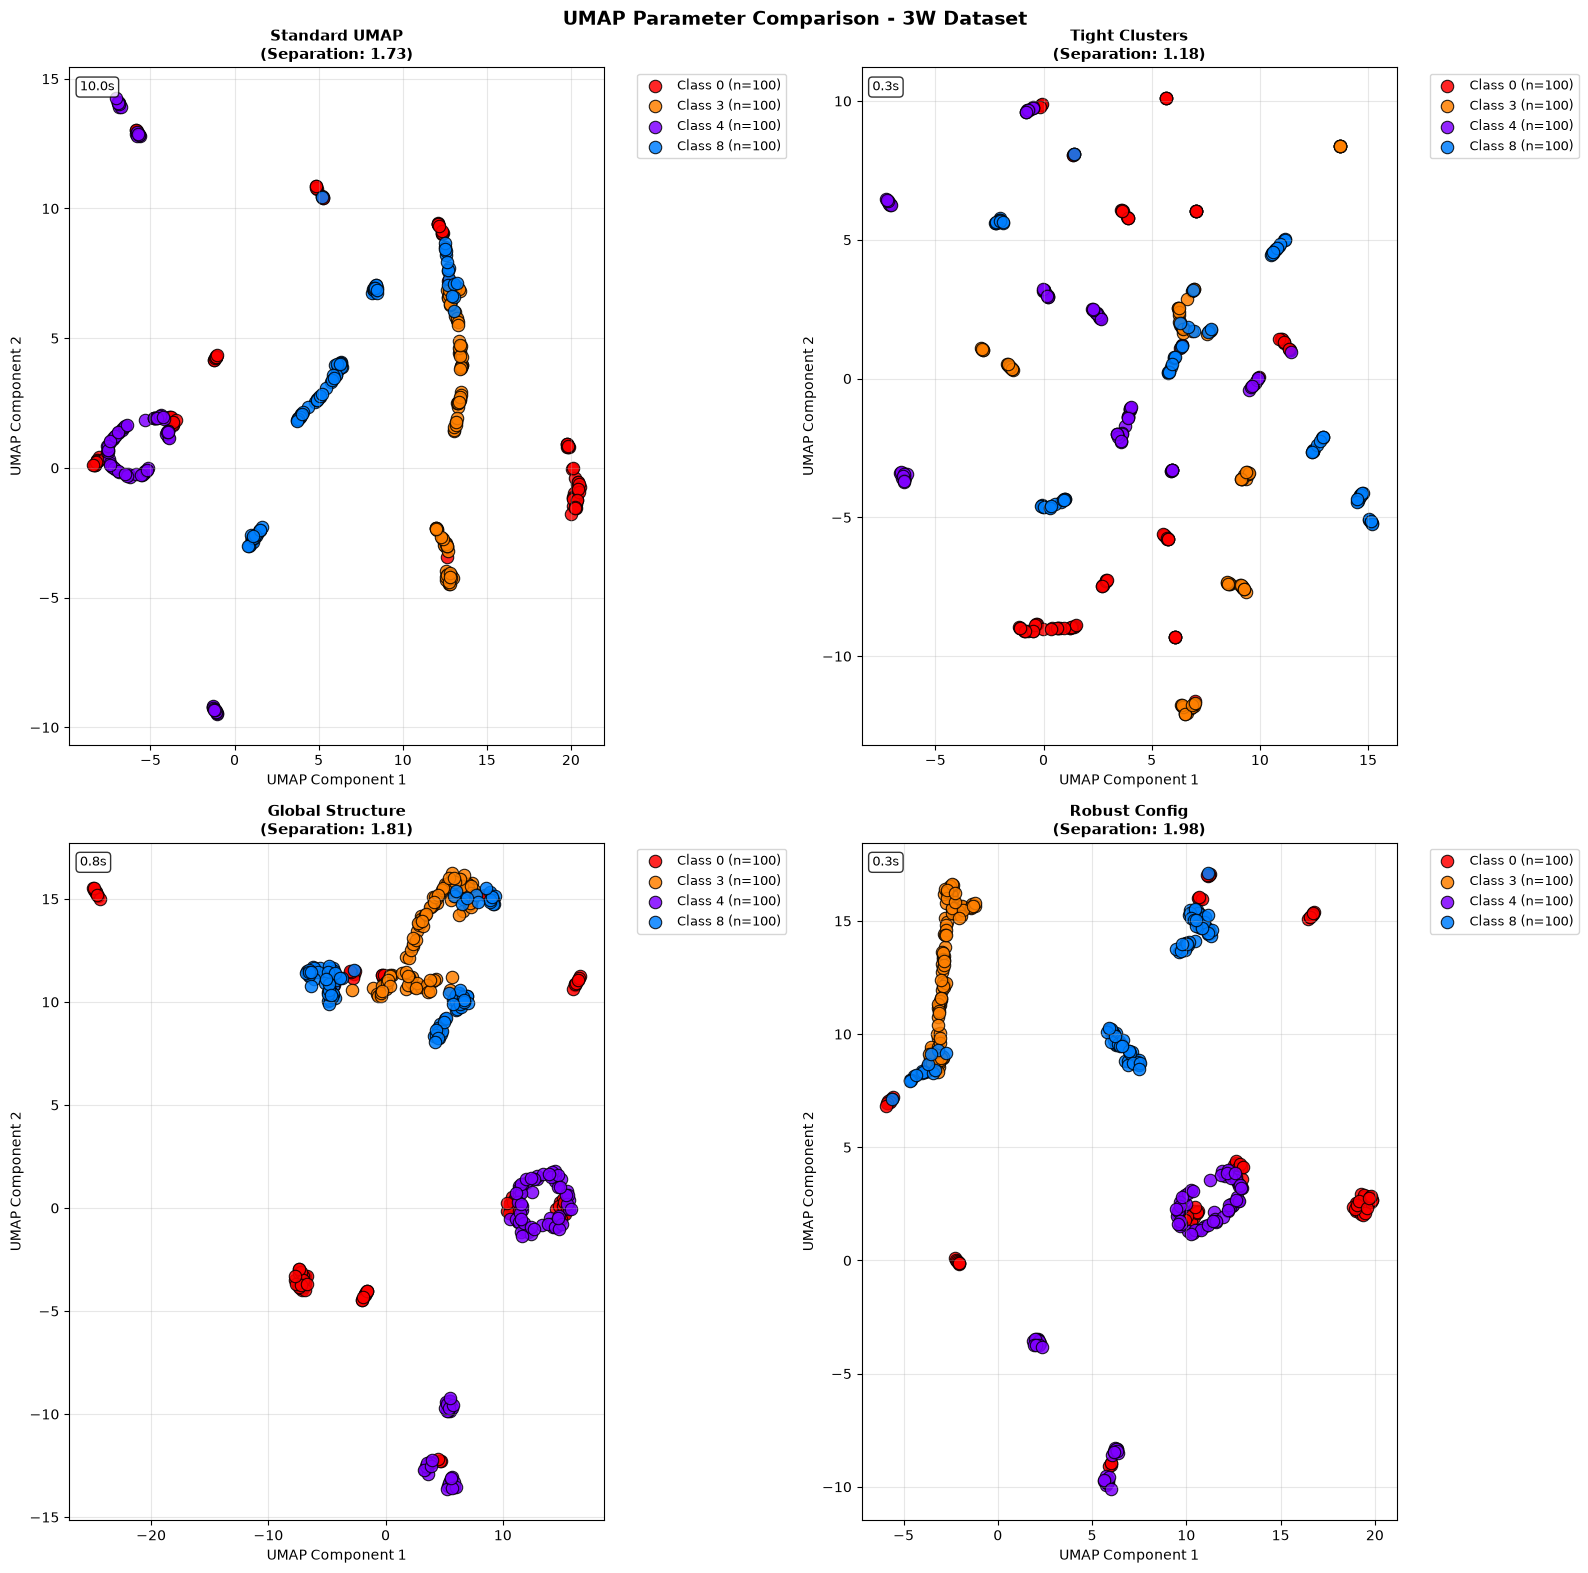


📊 UMAP Analysis Results:
⚡ Configuration Performance:
   • Config 1: 10.0s
   • Config 2: 0.3s ⚡ Fastest
   • Config 3: 0.8s
   • Config 4: 0.3s


In [9]:
# UMAP Visualization Analysis
if X_scaled is not None and y_labels is not None and umap_available:
    print("🚀 UMAP: Uniform Manifold Approximation")
    print("=" * 60)

    # Run UMAP analysis using existing methods
    umap_results = dim_reducer.run_umap_analysis(X_scaled, y_labels)

    if umap_results:
        # Create visualizations
        fig = dim_reducer.plot_dimensionality_reduction_results(
            umap_results, y_labels, "UMAP"
        )

        # Print performance summary
        dim_reducer.print_dimensionality_reduction_summary(umap_results, "UMAP")

elif not umap_available:
    print("❌ UMAP not available. Skipping UMAP analysis.")
else:
    print("❌ Cannot run UMAP: No processed data available")

## Method Comparison Analysis

**Choosing the right method:**

**Use t-SNE when:**
- **Small-medium datasets** (<10k samples)
- **Focus on clustering** - Want clear class separation
- **Exploratory analysis** - Looking for hidden patterns
- **Computational time not critical**

**Use UMAP when:**
- **Large datasets** (>10k samples)
- **Global structure matters** - Need to preserve overall relationships
- **Reproducibility required** - Consistent results needed
- **Speed is important** - Production visualization systems

**Interpretation guidelines:**
- **Tight clusters** - Strong class separability, good for classification
- **Overlapping regions** - Challenging classification boundaries
- **Outliers** - Potential data quality issues or rare patterns

> 📖 **In the book — Appendix E, §*Caderno 2*.** This notebook shows the **same cloud of points organized in four different ways** for each method (t-SNE with perplexity 10, 30 and 50 and different learning rates; UMAP with 5 to 50 neighbors and different metrics). That is the pedagogical point: **the projection is a choice, not a measurement**. When you read the "stability" and "deterministic" remarks above, remember that they hold only for a fixed seed and fixed parameters. The same caution applies to the latent-space figures of Chapters 9 and 12 of the book.
>
> 🔎 *Try it:* change `random_state=42` in `run_tsne_analysis` / `run_umap_analysis` (`src/visualization.py`) and check which conclusions about class separability survive.

In [10]:
# Method Comparison and Analysis
print("📊 Dimensionality Reduction Method Comparison")
print("=" * 60)

# Compare methods if both are available
if "tsne_results" in locals() and "umap_results" in locals():
    print("🏆 t-SNE vs UMAP Performance Comparison:")

    # Calculate average times
    tsne_times = [r["time"] for r in tsne_results if r["time"] is not None]
    umap_times = (
        [r["time"] for r in umap_results if r["time"] is not None]
        if umap_results
        else []
    )

    if tsne_times:
        avg_tsne_time = np.mean(tsne_times)
        print(f"   • t-SNE average time: {avg_tsne_time:.1f}s")

    if umap_times:
        avg_umap_time = np.mean(umap_times)
        print(f"   • UMAP average time: {avg_umap_time:.1f}s")

        if tsne_times:
            speedup = avg_tsne_time / avg_umap_time
            print(f"   • UMAP speedup: {speedup:.1f}x faster")

    print("\n📈 Method Characteristics:")
    print("   🔮 t-SNE:")
    print("      • Excellent for local structure preservation")
    print("      • Great for cluster visualization")
    print("      • Sensitive to perplexity parameter")
    print("      • Computationally intensive")

    if umap_available:
        print("   🚀 UMAP:")
        print("      • Preserves both local and global structure")
        print("      • Faster computation")
        print("      • More scalable to large datasets")
        print("      • Deterministic results")

print("\n✅ Visualization analysis complete!")
print("📝 Key insights:")
print("   • Both methods revealed class separability patterns")
print("   • Parameter tuning affects cluster quality")
print("   • Different metrics capture different data aspects")

📊 Dimensionality Reduction Method Comparison
🏆 t-SNE vs UMAP Performance Comparison:
   • t-SNE average time: 0.4s
   • UMAP average time: 2.9s
   • UMAP speedup: 0.1x faster

📈 Method Characteristics:
   🔮 t-SNE:
      • Excellent for local structure preservation
      • Great for cluster visualization
      • Sensitive to perplexity parameter
      • Computationally intensive
   🚀 UMAP:
      • Preserves both local and global structure
      • Faster computation
      • More scalable to large datasets
      • Deterministic results

✅ Visualization analysis complete!
📝 Key insights:
   • Both methods revealed class separability patterns
   • Parameter tuning affects cluster quality
   • Different metrics capture different data aspects
